In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
! unzip /content/drive/MyDrive/png.zip

Görüntülenen çıkış son 5000 satıra kısaltıldı.
  inflating: all/abnormal/S(83-167)0058.png  
  inflating: all/abnormal/S(83-167)0059.png  
  inflating: all/abnormal/S(83-167)0060.png  
  inflating: all/abnormal/S(83-167)0061.png  
  inflating: all/abnormal/S(83-167)0062.png  
  inflating: all/abnormal/S(83-167)0063.png  
  inflating: all/abnormal/S(83-167)0064.png  
  inflating: all/abnormal/S(83-167)0065.png  
  inflating: all/abnormal/S(83-167)0066.png  
  inflating: all/abnormal/S(83-167)0067.png  
  inflating: all/abnormal/S(83-167)0068.png  
  inflating: all/abnormal/S(83-167)0069.png  
  inflating: all/abnormal/S(83-167)0070.png  
  inflating: all/abnormal/S(83-167)0071.png  
  inflating: all/abnormal/S(83-167)0072.png  
  inflating: all/abnormal/S(83-167)0073.png  
  inflating: all/abnormal/S(83-167)0074.png  
  inflating: all/abnormal/S(83-167)0075.png  
  inflating: all/abnormal/S(83-167)0076.png  
  inflating: all/abnormal/S(83-167)0077.png  
  inflating: all/abnormal/S(83-16

In [5]:
import json
import numpy as np
from PIL import Image, ImageDraw
import os

# JSON dosyasını yükle
with open('annotations.json', 'r') as file:
    data = json.load(file)

# Görüntülerin kaydedildiği dizin
image_dir = '/content/all/abnormal/'

# Orijinal görüntülerin kaydedileceği dizin
originals_dir = '/content/drive/MyDrive/originals/'

# Maskelerin kaydedileceği dizin
masks_dir = '/content/drive/MyDrive/masks/'

# Gerekirse klasörleri oluştur
os.makedirs(originals_dir, exist_ok=True)
os.makedirs(masks_dir, exist_ok=True)

for image_info in data['images']:
    # İlgili annotasyonları bul
    annotations = [anno for anno in data['annotations'] if anno['image_id'] == image_info['id']]

    # Eğer görüntü için annotasyon yoksa, döngüde sonraki görüntüye geç
    if not annotations:
        continue

    # Görüntü dosyasını aç
    image_path = os.path.join(image_dir, image_info['file_name'])
    image = Image.open(image_path)
    width, height = image.size

    # Orijinal görüntüyü kaydet
    original_save_path = os.path.join(originals_dir, image_info['file_name'])
    image.save(original_save_path)

    # Binary maske için boş bir görüntü oluştur
    mask = Image.new('L', (width, height), 0)
    draw = ImageDraw.Draw(mask)

    for annotation in annotations:
        # 'segmentation' bilgisini kullanarak maskeyi çiz
        for segment in annotation['segmentation']:
            # Segmentasyon noktalarını çiftler halinde grupla (x, y)
            polygon = [(segment[i], segment[i+1]) for i in range(0, len(segment), 2)]
            draw.polygon(polygon, outline=255, fill=255)  # Beyaz dolgu ve çerçeve

    # Maskeyi kaydet
    mask_save_path = os.path.join(masks_dir, image_info['file_name'].replace('.png', '_mask.png'))
    mask.save(mask_save_path)

    print(f"Orijinal ve maske kaydedildi: {original_save_path}, {mask_save_path}")

Orijinal ve maske kaydedildi: /content/drive/MyDrive/originals/(60-107)0018.png, /content/drive/MyDrive/masks/(60-107)0018_mask.png
Orijinal ve maske kaydedildi: /content/drive/MyDrive/originals/(60-107)0019.png, /content/drive/MyDrive/masks/(60-107)0019_mask.png
Orijinal ve maske kaydedildi: /content/drive/MyDrive/originals/(60-107)0020.png, /content/drive/MyDrive/masks/(60-107)0020_mask.png
Orijinal ve maske kaydedildi: /content/drive/MyDrive/originals/(60-107)0021.png, /content/drive/MyDrive/masks/(60-107)0021_mask.png
Orijinal ve maske kaydedildi: /content/drive/MyDrive/originals/(60-107)0022.png, /content/drive/MyDrive/masks/(60-107)0022_mask.png
Orijinal ve maske kaydedildi: /content/drive/MyDrive/originals/(74-141)0049.png, /content/drive/MyDrive/masks/(74-141)0049_mask.png
Orijinal ve maske kaydedildi: /content/drive/MyDrive/originals/(74-141)0050.png, /content/drive/MyDrive/masks/(74-141)0050_mask.png
Orijinal ve maske kaydedildi: /content/drive/MyDrive/originals/(74-141)0051.

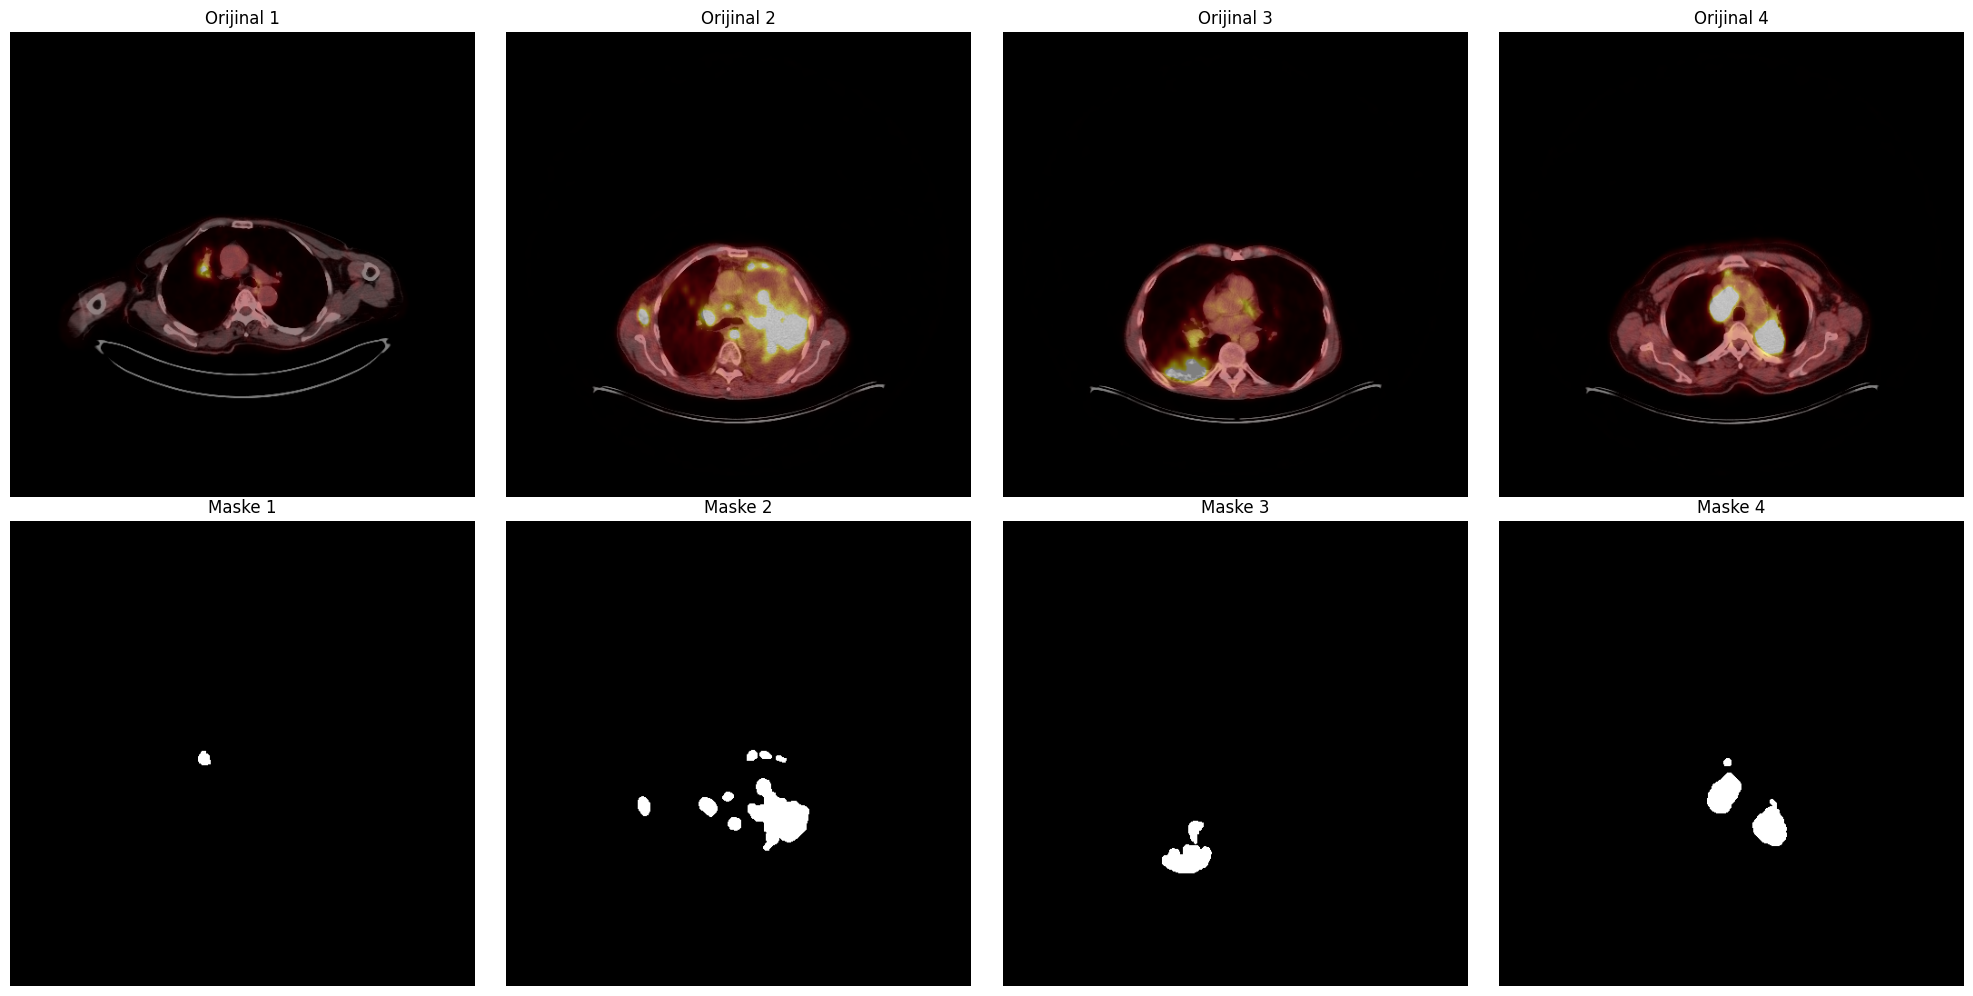

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

# Orijinal görüntülerin ve maskelerin kaydedildiği dizinler
originals_dir = '/content/drive/MyDrive/originals/'
masks_dir = '/content/drive/MyDrive/masks/'

# Orijinal görüntülerin listesini al
original_images = [f for f in os.listdir(originals_dir) if os.path.isfile(os.path.join(originals_dir, f))]

# 4 rastgele orijinal görüntü seç
selected_images = random.sample(original_images, 4)

# Görselleştirme
fig, axes = plt.subplots(2, 4, figsize=(20, 10))  # 2 satır ve 4 sütundan oluşan bir ızgara

for i, image_name in enumerate(selected_images):
    # Orijinal ve maskelenmiş görüntülerin tam yollarını oluştur
    original_image_path = os.path.join(originals_dir, image_name)
    masked_image_path = os.path.join(masks_dir, image_name.replace('.png', '_mask.png'))  # Maske dosyasının adını düzeltebilirsiniz

    # Görüntüleri yükle
    original_image = Image.open(original_image_path)
    masked_image = Image.open(masked_image_path)

    # Orijinal görüntüyü görselleştir
    axes[0, i].imshow(original_image)
    axes[0, i].set_title(f'Orijinal {i+1}')
    axes[0, i].axis('off')

    # Maskelenmiş görüntüyü görselleştir
    axes[1, i].imshow(masked_image, cmap='gray')
    axes[1, i].set_title(f'Maske {i+1}')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()


In [ ]:
import os
import numpy as np
from tensorflow.keras.preprocessing.image import img_to_array, load_img
from sklearn.model_selection import train_test_split

In [ ]:
def load_data(image_dir, mask_dir, image_size=(256, 256)):
    images = []  # Görüntüleri saklamak için boş liste
    masks = []   # Maskeleri saklamak için boş liste

    # Görüntü dosyalarının isimlerini al
    image_files = sorted([os.path.join(image_dir, file) for file in os.listdir(image_dir) if file.endswith('.png')])
    mask_files = sorted([os.path.join(mask_dir, file) for file in os.listdir(mask_dir) if file.endswith('_mask.png')])

    # Görüntüleri ve maskeleri yükle, ön işle ve listelere ekle
    for image_file, mask_file in zip(image_files, mask_files):
        # Görüntüyü yükle ve ön işle
        image = load_img(image_file, target_size=image_size, color_mode='grayscale')
        image = img_to_array(image) / 255.0  # Normalize et

        # Maskeyi yükle ve ön işle
        mask = load_img(mask_file, target_size=image_size, color_mode='grayscale')
        mask = img_to_array(mask) / 255.0
        mask = np.round(mask)  # Maskeleri binary hale getir

        images.append(image)
        masks.append(mask)

    # Listeleri Numpy dizilerine dönüştür
    images = np.array(images)
    masks = np.array(masks)

    return images, masks


In [ ]:
# Görüntü ve maske klasör yollarınızı belirtin
image_dir = '/content/drive/MyDrive/originals'
mask_dir = '/content/drive/MyDrive/masks'

# Veri setini yükle
images, masks = load_data(image_dir, mask_dir)

# Veri setini eğitim, doğrulama ve test setlerine ayır
X_train, X_test, y_train, y_test = train_test_split(images, masks, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42)  # 0.25 x 0.8 = 0.2

print(f"Eğitim seti boyutu: {X_train.shape}, Doğrulama seti boyutu: {X_val.shape}, Test seti boyutu: {X_test.shape}")


Eğitim seti boyutu: (591, 256, 256, 1), Doğrulama seti boyutu: (198, 256, 256, 1), Test seti boyutu: (198, 256, 256, 1)


In [ ]:
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, concatenate, Conv2DTranspose, Dropout
from tensorflow.keras.models import Model

def unet(input_size=(256, 256, 1)):
    inputs = Input(input_size)

    # Kodlayıcı
    c1 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(inputs)
    c1 = Dropout(0.1)(c1)
    c1 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c1)
    p1 = MaxPooling2D((2, 2))(c1)

    c2 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p1)
    c2 = Dropout(0.1)(c2)
    c2 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c2)
    p2 = MaxPooling2D((2, 2))(c2)

    c3 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p2)
    c3 = Dropout(0.2)(c3)
    c3 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c3)
    p3 = MaxPooling2D((2, 2))(c3)

    c4 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p3)
    c4 = Dropout(0.2)(c4)
    c4 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c4)
    p4 = MaxPooling2D(pool_size=(2, 2))(c4)

    c5 = Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p4)
    c5 = Dropout(0.3)(c5)
    c5 = Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c5)

    # Kod çözücü
    u6 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c5)
    u6 = concatenate([u6, c4])
    c6 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u6)
    c6 = Dropout(0.2)(c6)
    c6 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c6)

    u7 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c6)
    u7 = concatenate([u7, c3])
    c7 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u7)
    c7 = Dropout(0.2)(c7)
    c7 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c7)

    u8 = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(c7)
    u8 = concatenate([u8, c2])
    c8 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u8)
    c8 = Dropout(0.1)(c8)
    c8 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c8)

    u9 = Conv2DTranspose(16, (2, 2), strides=(2, 2), padding='same')(c8)
    u9 = concatenate([u9, c1], axis=3)
    c9 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u9)
    c9 = Dropout(0.1)(c9)
    c9 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c9)

    # Çıkış katmanı
    outputs = Conv2D(1, (1, 1), activation='sigmoid')(c9)

    model = Model(inputs=[inputs], outputs=[outputs])
    return model

# Modeli oluştur ve özetini yazdır
model = unet()
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 256, 256, 1)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 256, 256, 16)         160       ['input_1[0][0]']             
                                                                                                  
 dropout (Dropout)           (None, 256, 256, 16)         0         ['conv2d[0][0]']              
                                                                                                  
 conv2d_1 (Conv2D)           (None, 256, 256, 16)         2320      ['dropout[0][0]']             
                                                                                              

In [ ]:
results = model.fit(X_train, y_train, validation_data=(X_val, y_val), batch_size=32, epochs=50)

Epoch 1/50
19/19 [==============================] - 39s 866ms/step - loss: 0.1847 - accuracy: 0.9762 - val_loss: 0.0276 - val_accuracy: 0.9961
Epoch 2/50
19/19 [==============================] - 7s 352ms/step - loss: 0.0160 - accuracy: 0.9957 - val_loss: 0.0274 - val_accuracy: 0.9961
Epoch 3/50
19/19 [==============================] - 6s 340ms/step - loss: 0.0129 - accuracy: 0.9957 - val_loss: 0.0338 - val_accuracy: 0.9955
Epoch 4/50
19/19 [==============================] - 6s 342ms/step - loss: 0.0116 - accuracy: 0.9958 - val_loss: 0.0347 - val_accuracy: 0.9948
Epoch 5/50
19/19 [==============================] - 6s 342ms/step - loss: 0.0110 - accuracy: 0.9958 - val_loss: 0.0149 - val_accuracy: 0.9958
Epoch 6/50
19/19 [==============================] - 6s 341ms/step - loss: 0.0129 - accuracy: 0.9957 - val_loss: 0.0230 - val_accuracy: 0.9955
Epoch 7/50
19/19 [==============================] - 7s 344ms/step - loss: 0.0101 - accuracy: 0.9958 - val_loss: 0.0246 - val_accuracy: 0.9954
Epoch

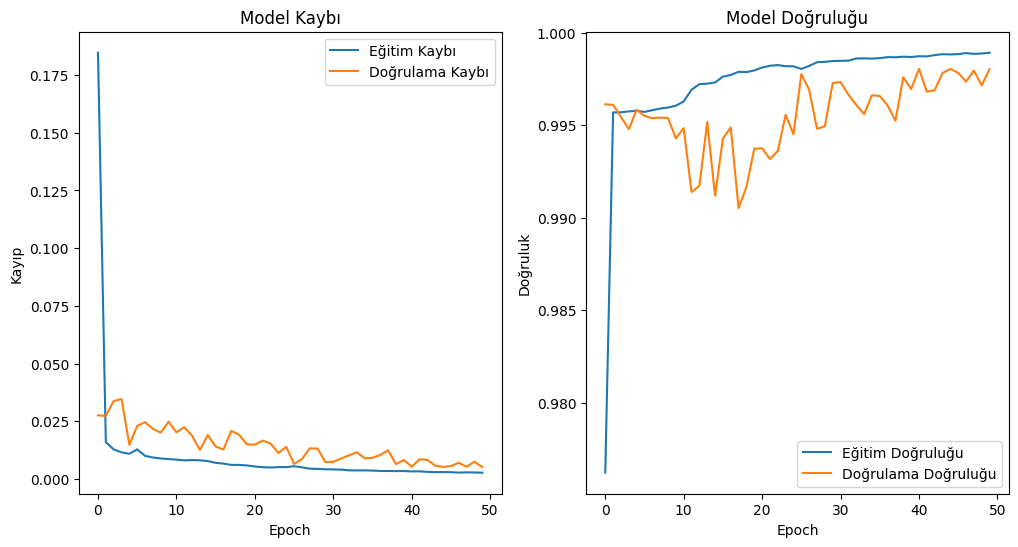

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(results.history['loss'], label='Eğitim Kaybı')
plt.plot(results.history['val_loss'], label='Doğrulama Kaybı')
plt.title('Model Kaybı')
plt.xlabel('Epoch')
plt.ylabel('Kayıp')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(results.history['accuracy'], label='Eğitim Doğruluğu')
plt.plot(results.history['val_accuracy'], label='Doğrulama Doğruluğu')
plt.title('Model Doğruluğu')
plt.xlabel('Epoch')
plt.ylabel('Doğruluk')
plt.legend()

plt.show()


In [ ]:
# Test seti üzerinde model performansını değerlendir
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test kaybı: {test_loss}, Test doğruluğu: {test_accuracy}")

7/7 [==============================] - 0s 63ms/step - loss: 0.0054 - accuracy: 0.9980
Test kaybı: 0.0053740208968520164, Test doğruluğu: 0.9979960918426514


In [ ]:
model.save('/content/drive/MyDrive/model_unet.h5')

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


7/7 [==============================] - 0s 66ms/step


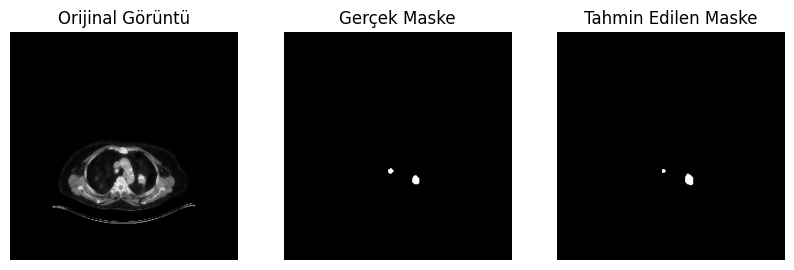

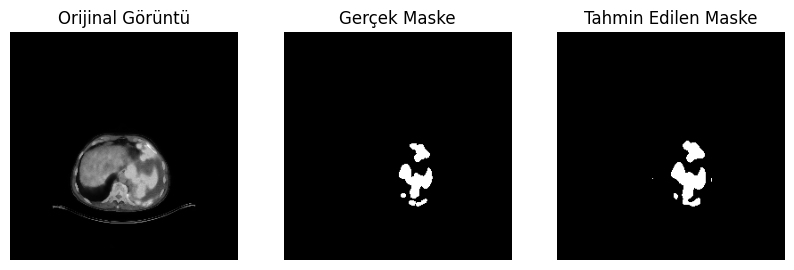

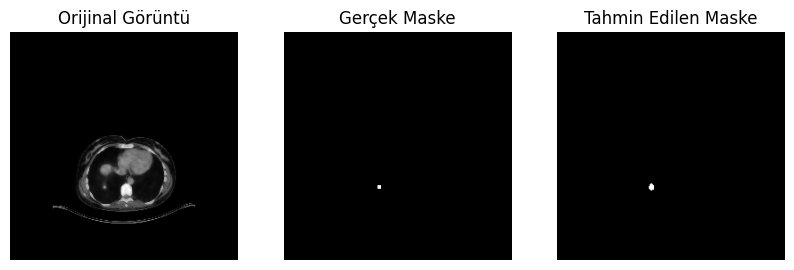

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_predictions(X, y, preds, num=3):
    indices = np.random.choice(range(len(X)), num, replace=False)

    for i, index in enumerate(indices):
        f, axarr = plt.subplots(1, 3, figsize=(10, 10))

        # Orijinal görüntü
        axarr[0].imshow(X[index].squeeze(), cmap='gray')
        axarr[0].set_title('Orijinal Görüntü')
        axarr[0].axis('off')

        # Gerçek maske
        axarr[1].imshow(y[index].squeeze(), cmap='gray')
        axarr[1].set_title('Gerçek Maske')
        axarr[1].axis('off')

        # Tahmin edilen maske
        pred_mask = preds[index].squeeze() > 0.5  # Sigmoid çıkışını binary maskeye dönüştür
        axarr[2].imshow(pred_mask, cmap='gray')
        axarr[2].set_title('Tahmin Edilen Maske')
        axarr[2].axis('off')

        plt.show()

# Test seti üzerinde tahminler yap
preds_test = model.predict(X_test, verbose=1)

# Test setinden örnekleri görselleştir
plot_predictions(X_test, y_test, preds_test, num=3)


In [ ]:
from tensorflow.keras.metrics import Precision, Recall
import numpy as np


In [ ]:
def calculate_iou(y_true, y_pred):
    intersection = np.logical_and(y_true, y_pred)
    union = np.logical_or(y_true, y_pred)
    iou_score = np.sum(intersection) / np.sum(union)
    return iou_score

def calculate_dice(y_true, y_pred):
    intersection = np.logical_and(y_true, y_pred)
    dice_score = 2 * np.sum(intersection) / (np.sum(y_true) + np.sum(y_pred))
    return dice_score


In [ ]:
# Basit test maskeleri oluştur
test_true_mask = np.array([[0, 1], [1, 1]])
test_pred_mask = np.array([[0, 1], [0, 1]])

# Test maskeleri için IoU ve Dice hesapla
test_iou = calculate_iou(test_true_mask, test_pred_mask)
test_dice = calculate_dice(test_true_mask, test_pred_mask)

print(f"Test IoU: {test_iou:.4f}")
print(f"Test Dice: {test_dice:.4f}")


Test IoU: 0.6667
Test Dice: 0.8000


-----------------------------------------------------------------------

In [6]:
import json
import os

def convert_bbox(size, box):
    """
    Bounding box koordinatlarını YOLO formatına dönüştürür.
    """
    dw = 1. / size[0]
    dh = 1. / size[1]
    x = (box[0] + box[2] / 2.0) * dw
    y = (box[1] + box[3] / 2.0) * dh
    w = box[2] * dw
    h = box[3] * dh
    return (x, y, w, h)

def create_yolo_labels(json_file, output_dir):
    # JSON dosyasını oku
    with open(json_file) as f:
        data = json.load(f)

    # Çıktı klasörünü oluştur
    os.makedirs(output_dir, exist_ok=True)

    # Her görüntü için bir metin dosyası oluştur
    for img in data['images']:
        # Görüntüye ait dosya adı
        filename = os.path.splitext(img['file_name'])[0] + '.txt'
        file_path = os.path.join(output_dir, filename)

        # Görüntüye ait annotasyonları bul
        img_annotations = [a for a in data['annotations'] if a['image_id'] == img['id']]

        # YOLO formatında annotasyonları dosyaya yaz
        with open(file_path, 'w') as f:
            for ann in img_annotations:
                # Sınıf ID'si (YOLO'da 0'dan başlar, varsayılan olarak 0 kullanılır)
                class_id = 0
                # Bounding box'ı YOLO formatına dönüştür
                bbox = convert_bbox((img['width'], img['height']), ann['bbox'])
                # Satırı dosyaya yaz
                f.write(f"{class_id} {' '.join(map(str, bbox))}\n")

# JSON dosyasının yolu ve çıktı klasörü
json_file = '/content/annotations.json'  # JSON dosyasının yolu
output_dir = '/content/cıktı'  # Etiket dosyalarının kaydedileceği klasör

create_yolo_labels(json_file, output_dir)


In [7]:
import os
import shutil

# Veri seti dizinleri
dataset_dir = '/content/yeni_abnormal2'
images_dir = '/content/yeni_abnormal2/yeni_originals2'
labels_dir = '/content/yeni_abnormal2/yeni_masks2'

# Eğitim, doğrulama ve test dizinleri
train_images_dir = os.path.join(images_dir, 'train')
val_images_dir = os.path.join(images_dir, 'val')
test_images_dir = os.path.join(images_dir, 'test')

train_labels_dir = os.path.join(labels_dir, 'train')
val_labels_dir = os.path.join(labels_dir, 'val')
test_labels_dir = os.path.join(labels_dir, 'test')

# Dizinlerin oluşturulması
os.makedirs(train_images_dir, exist_ok=True)
os.makedirs(val_images_dir, exist_ok=True)
os.makedirs(test_images_dir, exist_ok=True)
os.makedirs(train_labels_dir, exist_ok=True)
os.makedirs(val_labels_dir, exist_ok=True)
os.makedirs(test_labels_dir, exist_ok=True)



In [8]:
import os
import shutil
from sklearn.model_selection import train_test_split

# Mevcut görüntü ve etiket dizinlerinizin yolları
original_images_dir = '/content/drive/MyDrive/originals/'
original_labels_dir = '/content/drive/MyDrive/masks/'

# Görüntü ve etiket dosyalarının listelerini al
image_files = os.listdir(original_images_dir)
label_files = os.listdir(original_labels_dir)

# Eğitim, doğrulama ve test setlerine bölme (80% eğitim, 10% doğrulama, 10% test)
train_files, val_test_files = train_test_split(image_files, test_size=0.2, random_state=42)
val_files, test_files = train_test_split(val_test_files, test_size=0.5, random_state=42)

# Dosyaları kopyalama fonksiyonu
# Dosyaları kopyalama fonksiyonu
def copy_files(files, source_dir, dest_dir, is_label=False):
    for file in files:
        if is_label:
            # Etiket dosyası için dosya ismine '_mask' ekini ekleyerek kaynak dosyayı bul
            source_file = file.replace('.png', '_mask.png')
        else:
            source_file = file
        shutil.copy(os.path.join(source_dir, source_file), dest_dir)

# Görüntü dosyalarını ilgili dizinlere kopyala
copy_files(train_files, original_images_dir, train_images_dir)
copy_files(val_files, original_images_dir, val_images_dir)
copy_files(test_files, original_images_dir, test_images_dir)

# Etiket dosyalarını ilgili dizinlere kopyala
copy_files(train_files, original_labels_dir, train_labels_dir, is_label=True)
copy_files(val_files, original_labels_dir, val_labels_dir, is_label=True)
copy_files(test_files, original_labels_dir, test_labels_dir, is_label=True)


In [10]:
len(os.listdir("/content/yeni_abnormal2/yeni_originals2/test"))

99

In [11]:
# Eğitim, doğrulama ve test görüntü dosyalarının yollarını içeren .txt dosyalarını oluştur
def create_dataset_files(train_files, val_files, test_files, images_dir, output_dir):
    # Dosya yollarını kaydetme fonksiyonu
    def write_paths(files, subdir, filename):
        with open(os.path.join(output_dir, filename), 'w') as f:
            for file in files:
                f.write(os.path.join(subdir, file) + '\n')

    # Eğitim, doğrulama ve test setleri için dosya yollarını kaydet
    write_paths(train_files, 'train', 'train.txt')
    write_paths(val_files, 'val', 'val.txt')
    write_paths(test_files, 'test', 'test.txt')

# Veri seti dosyalarını oluştur
create_dataset_files(train_files, val_files, test_files, images_dir, '/content/dataset_files')

# Not: '/path/to/output' kısmını, oluşturulan dosyaların kaydedileceği gerçek dizin yolu ile değiştirin.


In [13]:
# config.yaml
path: '/content/yeni_abnormal2'  # Veri setinizin ana yolu
train: 'yeni_originals2/train/'  # Eğitim görüntülerinin yolu
val: 'yeni_originals2/val/'  # Doğrulama görüntülerinin yolu

# Sınıflar
nc: 1  # Sınıf sayısı, örneğinizdeki gerçek sınıf sayısına göre ayarlayın
names: ['Cancer']  # Sınıf adları listesi, gerçek sınıf adlarınızla değiştirin


In [27]:
import os

# Komutunuzu bir string olarak tanımlayın
command = "python train.py --img 256 --batch 16 --epochs 300 --data /content/config.yml --weights /content/yolov8x.pt"

# os.system fonksiyonunu kullanarak terminal komutunu çalıştırın
os.system(command)


256

In [30]:
pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 715.0/715.0 kB 9.9 MB/s eta 0:00:00


In [37]:
!python train.py --imgsz 640 --batch 16 --epochs 1 --data /content/config.yml --weights /content/yolov8n.pt

Ultralytics YOLOv8.1.14 🚀 Python-3.10.12 torch-2.1.0+cu121 CPU (Intel Xeon 2.20GHz)
engine/trainer: task=detect, mode=train, model=yolov8n.pt, data=/content/config.yml, epochs=1, time=None, patience=50, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train4, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_labels=True, show_conf=True, show_boxes=True,